# Walkthrough: cloud-free Sentinel-2 mosaic, Steps 2-4

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/blob/main/notebooks/sentinel2_walkthrough.ipynb)

This notebook runs Steps 2-4 of the pipeline on public Sentinel-2 data and shows
the intermediate and final products:

1. Download small subsets of six Sentinel-2 L2A scenes over central-western
   Taiwan (about 22 km x 22 km) from the public
   [Earth Search](https://earth-search.aws.element84.com/v1) catalogue. No account
   is needed. Three partly cloudy scenes are mosaicked; three mostly clear
   scenes are candidates for filling the clouds.
2. **Step 2**: find seamlines between overlapping scenes and build the
   multispectral (XS) mosaic and its cloud mask.
3. **Step 3**: build the panchromatic (Pan) mosaic along the same seamlines.
4. **Step 4**: fill the clouds in both mosaics from the candidate scenes.

Step 1 (colour balancing in ERDAS IMAGINE) is skipped; the scenes go into
Step 2 as delivered.

The notebook uses the functions of `examples/sentinel2_demo/run_demo.py`, which
runs the same workflow from the command line. On Colab the whole notebook takes
about 5 minutes; nothing needs to be installed on your computer.

## 1. Setup

On Colab, the next cell clones the repository and installs the GDAL
command-line tools and the Python dependencies (about 1 minute). Run locally,
it uses the repository this notebook is in; install the dependencies first as
described in the README.

In [1]:
import pathlib
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline.git"
BRANCH = "main"

def sh(command):
    """Run a shell command and stop with its output if it fails."""
    result = subprocess.run(command, shell=True, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError(f"failed: {command}")

if IN_COLAB:
    REPO = pathlib.Path("/content/cloud-mosaic")
    if not REPO.exists():
        sh(f"git clone --depth 1 --branch {BRANCH} {REPO_URL} {REPO}")
    sh("apt-get -qq update && apt-get -qq install -y gdal-bin")
    # The pipeline needs OpenCV < 4.11 (see requirements.txt); Colab ships a newer
    # one in several packages that all provide cv2, so remove those first.
    sh("pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python")
    sh(f"pip install -q -r {REPO}/requirements.txt")
else:
    REPO = pathlib.Path.cwd().resolve().parent   # notebooks/ -> repository root

import cv2
print("repository:", "/content/cloud-mosaic" if IN_COLAB else REPO.name)
print("OpenCV", cv2.__version__)
print(subprocess.run(["gdalinfo", "--version"], capture_output=True, text=True).stdout.strip())

repository: nbrun
OpenCV 4.10.0
GDAL 3.13.3 "Iowa City", released 2026/08/13


In [2]:
import importlib.util
import json
import shutil

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Load the demo script as a module, to reuse its download and set-up functions.
spec = importlib.util.spec_from_file_location("run_demo", REPO / "examples" / "sentinel2_demo" / "run_demo.py")
demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(demo)

WORK = REPO / "demo_output"          # data and outputs (ignored by git)
DATA = WORK / "data"
S2, S3, S4 = WORK / "step2", WORK / "step3", WORK / "step4"

mpl.rcParams.update({
    "font.size": 12, "axes.labelsize": 13, "legend.fontsize": 11,
    "font.weight": "bold", "axes.labelweight": "bold",
    "axes.linewidth": 1.6, "axes.edgecolor": "black",
    "figure.dpi": 72, "savefig.dpi": 300,
})
WONG = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
LINESTYLES = ["-", "--", "-."]

Helpers for the figures: a true-colour image (red, green, blue) with a 2-98 %
contrast stretch, drawn in map coordinates (TWD97, km) so that scenes with
different extents line up.

In [3]:
def extent_km(src):
    b = src.bounds
    return [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]

def stretch_limits(*paths):
    """2nd and 98th percentiles of the red, green and blue bands over the valid pixels of all files."""
    values = []
    for p in paths:
        with rasterio.open(p) as src:
            rgb = src.read([3, 2, 1]).astype(float)
        valid = np.all(rgb > 0, axis=0)
        values.append(rgb[:, valid])
    v = np.concatenate(values, axis=1)
    return np.percentile(v, 2, axis=1), np.percentile(v, 98, axis=1)

def show_rgb(ax, path, limits):
    """Draw a true-colour image; no-data pixels stay white."""
    lo, hi = limits
    with rasterio.open(path) as src:
        rgb = src.read([3, 2, 1]).astype(float)
        ext = extent_km(src)
    valid = np.all(rgb > 0, axis=0)
    img = np.clip((rgb - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1).transpose(1, 2, 0)
    rgba = np.dstack([img, valid.astype(float)])
    ax.imshow(rgba, extent=ext)
    return ext

def outline(ax, path, condition, color, linestyle="-", linewidth=1.4):
    """Contour of the pixels of the first band of *path* where condition(values) holds."""
    with rasterio.open(path) as src:
        a = condition(src.read(1)).astype(float)
        ext = extent_km(src)
    x = np.linspace(ext[0], ext[1], a.shape[1])
    y = np.linspace(ext[3], ext[2], a.shape[0])
    ax.contour(x, y, a, levels=[0.5], colors=[color], linestyles=[linestyle], linewidths=linewidth)

def label(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", ha="left", fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="black", linewidth=1.0, pad=2.5))

def map_axes(ax, ext):
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.set_xlabel("x [km]"); ax.set_aspect("equal")
    ax.locator_params(nbins=4)

## 2. Download the Sentinel-2 scenes

Each scene is reprojected to TWD97 (`EPSG:3826`) and converted to the pipeline's
inputs: a 4-band XS scene (blue, green, red, near-infrared at 20 m, 12-bit), a
Pan scene (Sentinel-2 has no panchromatic band, so the mean of the 10 m visible
bands stands in for it) and a cloud mask from the Sentinel-2 scene
classification, buffered by 200 m. The three scenes to mosaic are cut to tilted
north-south strips that imitate separate satellite swaths.

The download is skipped if the data are already there.

In [4]:
if demo.missing_data(DATA):
    demo.download(DATA)
else:
    print("Data already downloaded in", DATA.relative_to(REPO))

scenes = [(name, item) for name, item, _ in demo.PRIMARY]
candidates = [(name, item) for name, item, _ in demo.CANDIDATES]
pd.DataFrame(
    [(n, i.split("_")[2], "mosaic") for n, i in scenes] + [(n, i.split("_")[2], "candidate") for n, i in candidates],
    columns=["file name", "acquisition date", "role"])

  a0000003 <- S2B_51QTG_20231126_0_L2A


    cloud cover 30%
  a0000001 <- S2A_51QTG_20231022_0_L2A


    cloud cover 27%
  a0000005 <- S2A_51QTG_20230922_0_L2A


    cloud cover 26%
  a0000101 <- S2A_51QTG_20231121_0_L2A


  a0000103 <- S2A_51QTG_20231101_0_L2A


  a0000105 <- S2A_51QTG_20231012_0_L2A


,file name,acquisition date,role
0,a0000003,20231126,mosaic
1,a0000001,20231022,mosaic
2,a0000005,20230922,mosaic
3,a0000101,20231121,candidate
4,a0000103,20231101,candidate
5,a0000105,20231012,candidate


**Figure 1.** (a-c) The three scenes to mosaic, with the outlines of their
cloud masks (orange). (d) The footprints of the three scenes in the demo area;
neighbouring strips overlap by about 3 km.

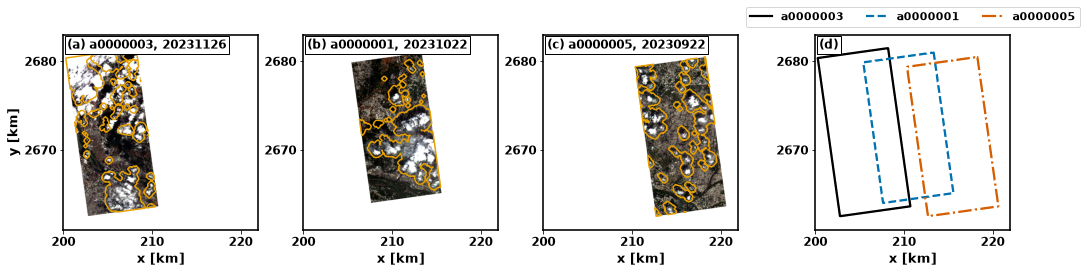

In [5]:
scene_files = [DATA / "scenes" / f"{n}.img" for n, _ in scenes]
mask_files = [DATA / "cloud_masks" / f"{n}_cloud.tif" for n, _ in scenes]
limits = stretch_limits(*scene_files)
aoi_km = [demo.AOI[0] / 1000, demo.AOI[2] / 1000, demo.AOI[1] / 1000, demo.AOI[3] / 1000]

fig, axes = plt.subplots(1, 4, figsize=(15, 5.2), constrained_layout=True)
for k, (ax, f, m, (name, item)) in enumerate(zip(axes, scene_files, mask_files, scenes)):
    show_rgb(ax, f, limits)
    outline(ax, m, lambda a: a > 0, WONG[1])
    map_axes(ax, aoi_km)
    label(ax, f"({'abc'[k]}) {name}, {item.split('_')[2]}")
axes[0].set_ylabel("y [km]")
ax = axes[3]
for k, f in enumerate(scene_files):
    outline(ax, f, lambda a: a > 0, WONG[[0, 5, 6][k]], LINESTYLES[k], 2.2)
map_axes(ax, aoi_km)
ax.legend([Line2D([], [], color=WONG[[0, 5, 6][k]], linestyle=LINESTYLES[k], linewidth=2.2) for k in range(3)],
          [n for n, _ in scenes], loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=True)
label(ax, "(d)")
plt.show()

**Figure 2.** The three mostly clear candidate scenes that Step 4 uses to fill
clouds, with the outlines of their own cloud masks (orange).

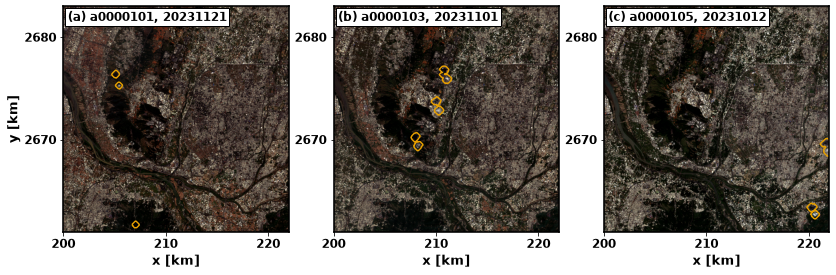

In [6]:
cand_files = [DATA / "candidates" / f"{n}.img" for n, _ in candidates]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.6), constrained_layout=True)
for k, (ax, f, (name, item)) in enumerate(zip(axes, cand_files, candidates)):
    show_rgb(ax, f, limits)
    outline(ax, DATA / "cloud_masks" / f"{name}_cloud.tif", lambda a: a > 0, WONG[1])
    map_axes(ax, aoi_km)
    label(ax, f"({'abc'[k]}) {name}, {item.split('_')[2]}")
axes[0].set_ylabel("y [km]")
plt.show()

## 3. Set up the step folders and parameter files

Each step runs in its own folder, with its inputs and a JSON parameter file
(`para.txt`, `para_pan.txt`, `para_cld.txt`), laid out as described in the
README. The parameters for Step 4 are shown below; `cloud_tolerance` and
`ssim_threshold` decide which candidates may fill a cloud patch.

In [7]:
demo.set_up_steps(WORK, DATA)
demo.write_configs(WORK)
# (paths shortened to demo_output/... for display)
print((S4 / "para_cld.txt").read_text().replace(str(WORK), "demo_output"))

{
 "res": "20.0",
 "trueBits": "12",
 "CandiImgPath": "demo_output/step4/cloud_database",
 "CldMaskPath": "demo_output/step4/cldDatabase",
 "MosaicImgAddress": "demo_output/step4/mosaic_xs.tif",
 "MosaicCldAddress": "demo_output/step4/mosaic_cloudmask.tif",
 "CandiMaskFolderName": "cloud_masks",
 "PanMosaicImgAddress": "demo_output/step4/mosaic_pan.tif",
 "pan_res": "10.0",
 "seaBorderAddress": "demo_output/step4/land_sea_mask.tif",
 "PanImgAddress": "demo_output/step4/raw_pan",
 "cloud_tolerance": "0.25",
 "ssim_threshold": "0.75",
 "canvas_crs": "EPSG:3826"
}


In [8]:
def run_step(script, folder):
    """Run one pipeline step in *folder*; print the end of its output."""
    result = subprocess.run([sys.executable, str(REPO / script)], cwd=folder,
                            capture_output=True, text=True)
    lines = [l for l in result.stdout.splitlines() if l.strip()]
    if result.returncode != 0:
        print("\n".join(lines[-40:]), result.stderr[-4000:])
        raise RuntimeError(f"{script} failed")
    print("\n".join(lines[-6:]))

## 4. Step 2: seamlines and the XS mosaic

Step 2 starts from the scene whose file name sorts first and adds the others in
order of distance from it. Between each new scene and the mosaic so far, it
finds a seamline through the overlap that avoids clouds and strong edges, and
blends the two along it. It also mosaics the cloud masks.

In [9]:
run_step("step2_mosaic/step2mosaic.py", S2)
print("processing order:", (S2 / "ProcessOrder.txt").read_text())

Writing result: a0000003 band: 2 to disk...
Writing result: a0000003 band: 3 to disk...
Writing result: a0000003 band: 4 to disk...
Writing cloud mask to disk...
All done!
Total time spent(hr): 0.0004500209952756349
processing order: ['a0000001.img', 'a0000005.img', 'a0000003.img']


**Figure 3.** (a) The XS mosaic after Step 2 with the seamlines (black on
white) and the outline of the mosaicked cloud mask (orange). (b) The mosaicked
cloud mask: these are the pixels that Step 4 tries to fill.

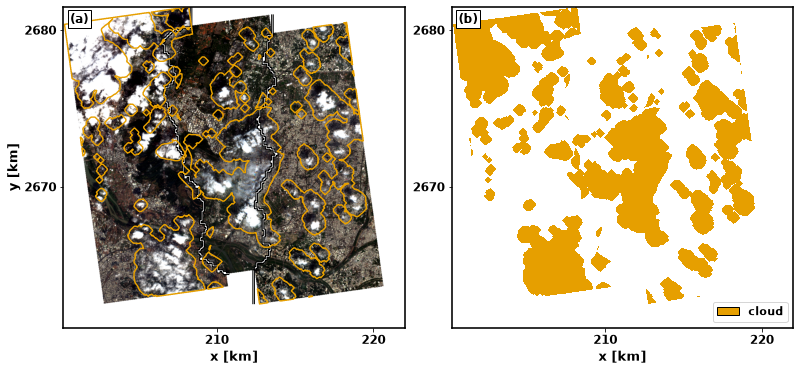

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), constrained_layout=True)
ax = axes[0]
ext = show_rgb(ax, S2 / "mosaic_xs.tif", limits)
for f in sorted(S2.glob("*_seamline.img")):
    with rasterio.open(f) as src:
        seam = src.read(1) == 1
        e = extent_km(src)
    ax.imshow(np.ma.masked_where(~seam, seam), extent=e, cmap=mpl.colors.ListedColormap(["white"]),
              interpolation="none")
    outline(ax, f, lambda a: a == 1, "black", "-", 1.0)
outline(ax, S2 / "mosaic_cloudmask.tif", lambda a: a == 1, WONG[1])
map_axes(ax, ext); ax.set_ylabel("y [km]"); label(ax, "(a)")
ax = axes[1]
with rasterio.open(S2 / "mosaic_cloudmask.tif") as src:
    cm = src.read(1)
    e = extent_km(src)
ax.imshow(np.where(cm == 1, 1.0, np.nan), extent=e, cmap=mpl.colors.ListedColormap([WONG[1]]), interpolation="none")
map_axes(ax, ext); label(ax, "(b)")
ax.legend(handles=[Patch(facecolor=WONG[1], edgecolor="black", label="cloud")], loc="lower right")
plt.show()

## 5. Step 3: the Pan mosaic

Step 3 mosaics the Pan scenes along the same seamlines, using the blend weights
that Step 2 wrote (`*_seamline_polygon.img`).

In [11]:
demo.copy_matching(S2, S3, ["transform.npy", "ImgInd.npy", "allWindow.npy", "Union_gt.npy",
                            "ProcessOrder.txt", "*_seamline_polygon.img", "*_seamline_polygon.img.aux.xml"])
run_step("step3_pan_mosaic/mosaicPan_block_rs.py", S3)

Mosaicking and writing to disk...
Image Process Progress: 3 / 3
Clipping...
Mosaicking and writing to disk...
All done!
Total time spent(hr): 9.772493056112177e-05


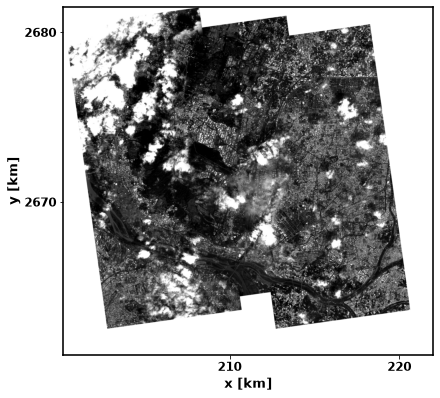

In [12]:
with rasterio.open(S3 / "mosaic_pan.tif") as src:
    pan = src.read(1).astype(float)
    e = extent_km(src)
valid = pan > 0
lo, hi = np.percentile(pan[valid], [2, 98])
fig, ax = plt.subplots(figsize=(6, 5.6), constrained_layout=True)
ax.imshow(np.where(valid, np.clip((pan - lo) / (hi - lo), 0, 1), np.nan), extent=e, cmap="gray")
map_axes(ax, e); ax.set_ylabel("y [km]")
plt.show()

**Figure 4.** The Pan mosaic after Step 3 (10 m).

## 6. Step 4: cloud filling

For each cloud patch, Step 4 scores the candidate scenes by their structural
similarity (SSIM) to the mosaic around the patch and by their own cloud cover.
The best candidate above the SSIM threshold fills the patch by Poisson
blending, in both the XS and the Pan mosaic. Patches that touch the edge of the
mosaic, or for which no candidate passes, stay unfilled.

In [13]:
demo.copy_matching(S2, S4, ["mosaic_xs.tif", "mosaic_cloudmask.tif", "allWindow.npy",
                            "transform.npy", "ProcessOrder.txt"])
demo.copy_matching(S3, S4, ["mosaic_pan.tif"])
for f in ("mosaic_xs.tif", "mosaic_pan.tif", "mosaic_cloudmask.tif"):
    shutil.copy(S4 / f, S4 / f.replace(".tif", "_raw.tif"))   # keep the mosaics before filling
run_step("step4_cloud_removal/step4cloud_removal.py", S4)

result = demo.check_results(S4)
print(f"Cloudy area filled: {result['fill_fraction']:.0%}")

cldzeroNum: 1
zeroExist: 0
right,up,left,low: 0 0 0 0
All done!
17 / 26  reconstructions of cloud-contaminated area
time(hr): 0.0008202381711129823
Cloudy area filled: 76%


**Figure 5.** (a) The XS mosaic before Step 4, with the outline of the clouds
(orange). (b) The XS mosaic after Step 4, with the outline of the clouds left
unfilled. (c) Which cloud pixels were filled (blue) and which were left (orange).

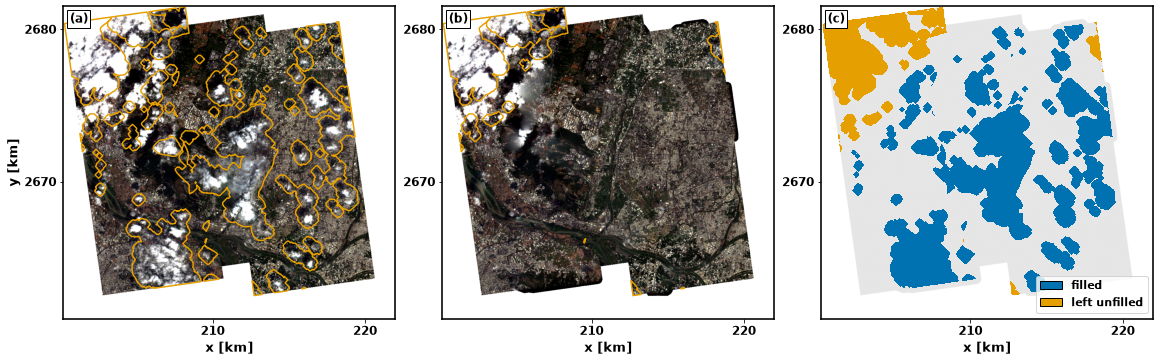

In [14]:
with rasterio.open(S4 / "mosaic_cloudmask_raw.tif") as src:
    before = src.read(1) == 1
    e = extent_km(src)
with rasterio.open(S4 / "mosaic_cloudmask.tif") as src:
    after = src.read(1) == 1
status = np.full(before.shape, np.nan)
status[before & ~after] = 0          # filled
status[after] = 1                    # left unfilled

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), constrained_layout=True)
for k, (ax, f) in enumerate(zip(axes[:2], ["mosaic_xs_raw.tif", "mosaic_xs.tif"])):
    show_rgb(ax, S4 / f, limits)
    mask = "mosaic_cloudmask_raw.tif" if k == 0 else "mosaic_cloudmask.tif"
    outline(ax, S4 / mask, lambda a: a == 1, WONG[1])
    map_axes(ax, e); label(ax, f"({'ab'[k]})")
axes[0].set_ylabel("y [km]")
ax = axes[2]
with rasterio.open(S4 / "mosaic_xs.tif") as src:
    footprint = np.all(src.read() > 0, axis=0)
ax.imshow(np.where(footprint, 0.9, np.nan), extent=e, cmap="gray", vmin=0, vmax=1)
ax.imshow(status, extent=e, cmap=mpl.colors.ListedColormap([WONG[5], WONG[1]]), vmin=0, vmax=1,
          interpolation="none")
map_axes(ax, e); label(ax, "(c)")
ax.legend(handles=[Patch(facecolor=WONG[5], edgecolor="black", label="filled"),
                   Patch(facecolor=WONG[1], edgecolor="black", label="left unfilled")], loc="lower right")
plt.show()

Step 4 writes `fill_log.csv` with one row per candidate it tried for each cloud
patch: the candidate, its SSIM, whether it filled the patch, and if not, why.

In [15]:
log = pd.read_csv(S4 / "fill_log.csv")
log.head(10)

,window,patch,candidate,ssim,clear_fraction,filled,pixels,note,x_min,y_min,x_max,y_max
0,0,10_cld.img,a0000103.img,0.9867,1.0000,yes,1498,NaN,208500.0,2677420.0,209800.0,2678620.0
1,0,11_cld.img,a0000103.img,0.8877,0.9482,yes,127705,NaN,205780.0,2665800.0,214620.0,2678880.0
2,0,12_cld.img,a0000103.img,0.9880,1.0000,yes,1352,NaN,212820.0,2677940.0,214020.0,2679160.0
3,0,13_cld.img,a0000103.img,0.8387,1.0000,yes,1882,NaN,212520.0,2679060.0,213880.0,2680460.0
4,0,14_cld.img,a0000103.img,0.9757,1.0000,yes,5448,NaN,211080.0,2677780.0,213140.0,2680520.0
5,0,15_cld.img,a0000103.img,0.8277,1.0000,yes,92622,NaN,213780.0,2666580.0,219880.0,2680680.0
6,0,16_cld.img,NaN,0.6458,NaN,no,5613,no candidate reaches ssim_threshold,217260.0,2677600.0,218980.0,2680820.0
7,0,17_cld.img,a0000103.img,0.8948,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0
8,0,17_cld.img,a0000105.img,0.8852,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0
9,0,17_cld.img,a0000101.img,0.8792,NaN,no,20776,cloud reaches the edge of the candidate overla...,205400.0,2676900.0,208800.0,2681000.0


## 7. Next steps

- The final products are in `demo_output/step4/`: `mosaic_xs.tif`,
  `mosaic_pan.tif` and `mosaic_cloudmask.tif` (0 = clear or filled, 1 = cloud
  left unfilled, 10/20 = flagged by the selected candidate's cloud mask). On
  Colab, download them from the file browser on the left.
- Change `cloud_tolerance` or `ssim_threshold` in `demo_output/step4/para_cld.txt`
  and rerun section 6 to see how the fill changes. The
  [CloudPeel explorer](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/cloudpeel/)
  shows this for several regions without running anything.
- To run the pipeline on your own scenes, see the README of each step and the
  [documentation website](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/).